In [7]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [8]:
df = pd.read_csv("iris_dataset.csv")

In [9]:
df.head(5) , df.tail(5)

(   sepal_length  sepal_width  petal_length  petal_width species
 0           5.1          3.5           1.4          0.2  setosa
 1           4.9          3.0           1.4          0.2  setosa
 2           4.7          3.2           1.3          0.2  setosa
 3           4.6          3.1           1.5          0.2  setosa
 4           5.0          3.6           1.4          0.2  setosa,
      sepal_length  sepal_width  petal_length  petal_width    species
 145           6.7          3.0           5.2          2.3  virginica
 146           6.3          2.5           5.0          1.9  virginica
 147           6.5          3.0           5.2          2.0  virginica
 148           6.2          3.4           5.4          2.3  virginica
 149           5.9          3.0           5.1          1.8  virginica)

In [10]:
df.shape

(150, 5)

In [11]:
print("Dataset Information : ")
print(df.info)

print("\n Missing Values : ")
df.isnull()


Dataset Information : 
<bound method DataFrame.info of      sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]>

 Missing Values : 


,sepal_length,sepal_width,petal_length,petal_width,species
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [12]:
print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

print("\nSpecies Distribution:")
print(df["species"].value_counts())


Duplicate Rows: 1

Statistical Summary:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# Data Analysis

### Species Distribution

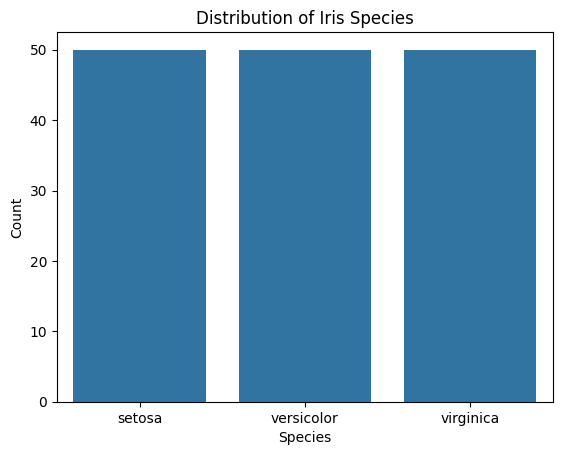

In [13]:
sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

## Correlation Heatmap 

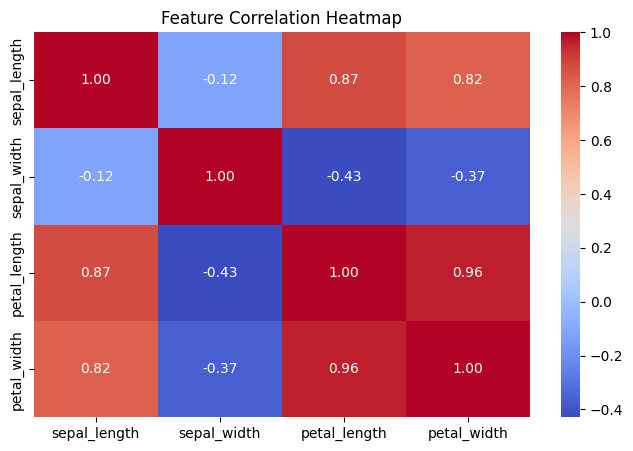

In [14]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include="number").corr(), annot=True,
    cmap="coolwarm", fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

## Pair Plot 

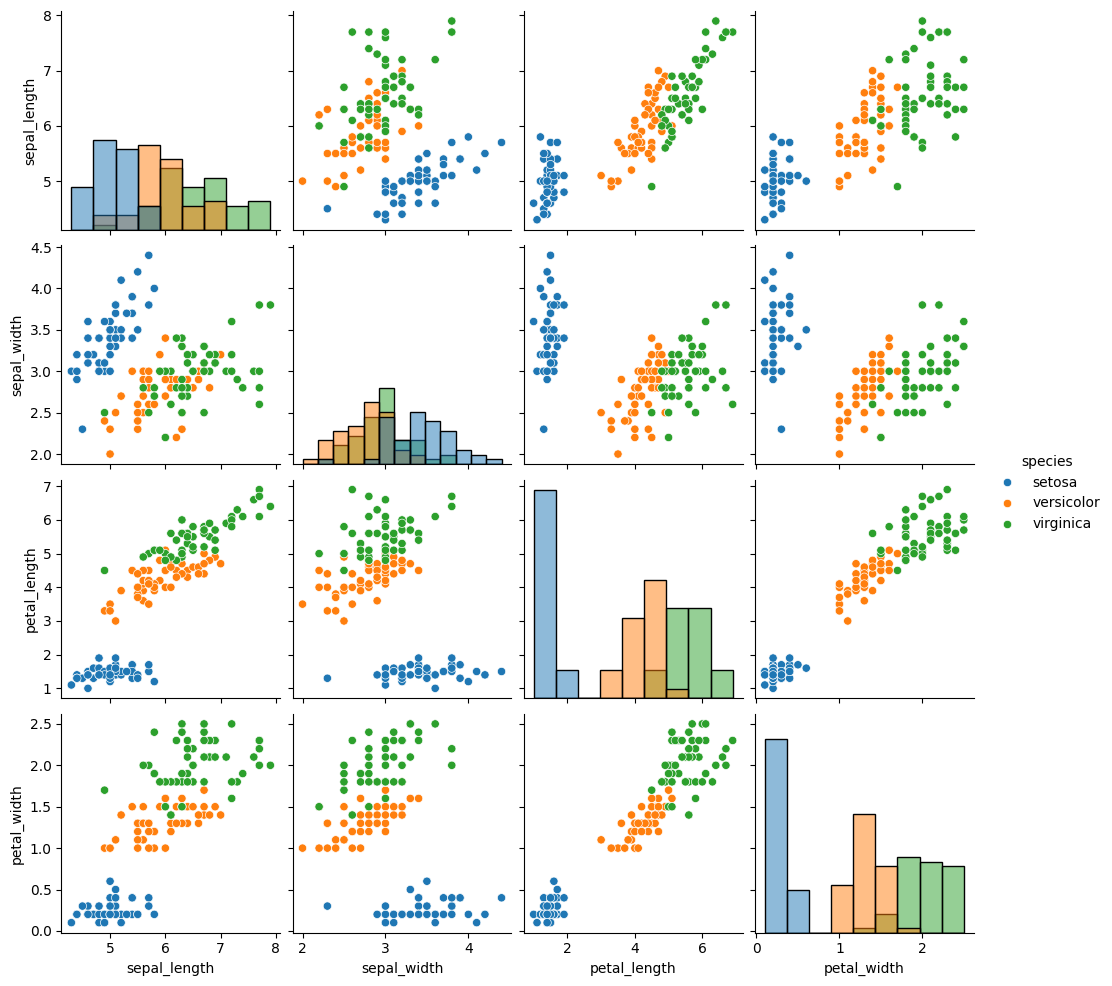

In [15]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

# Seprating Feature and Target Values 

In [16]:
X = df.drop(columns = ["species"])
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

Features shape: (150, 4)
Target shape: (150,)

Feature columns:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

Target classes:
['setosa' 'versicolor' 'virginica']


In [17]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=43 , stratify = y)
print("Training Samples : ",X_train.shape[0])
print("\n Testing Samples : ", X_test.shape[0])

Training Samples :  120

 Testing Samples :  30


## Training Logistic Regression and Decision Tree

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier


models = {"Logistic Regression " : Pipeline([("scaler",StandardScaler()) , ("model" , LogisticRegression(max_iter=1000))]) ,
           "Decision Tree": Pipeline([("scaler", StandardScaler()),  ("model", DecisionTreeClassifier( random_state=42,
            max_depth=4))])
         }

In [19]:
for name , model in models.items():
    model.fit(X_train , y_train)
    print(name , "Trained Succesfully")

Logistic Regression  Trained Succesfully
Decision Tree Trained Succesfully


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

print("Model Benchmark Results:")
display(results_df.round(4))

Model Benchmark Results:


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.9667,0.9697,0.9667,0.9666
Decision Tree,0.9667,0.9697,0.9667,0.9666


In [22]:
for name, y_pred in predictions.items():
    print("\n", "=" * 45)
    print("Model:", name)
    print("=" * 45)
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=models[name].classes_,
            zero_division=0
        )
    )


Model: Logistic Regression 
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Model: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## Comparing Models 

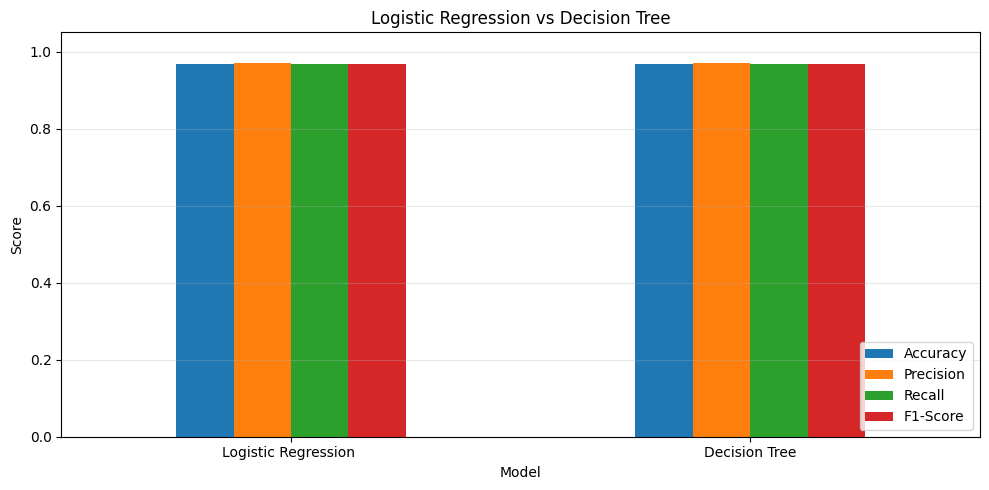

In [23]:
results_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

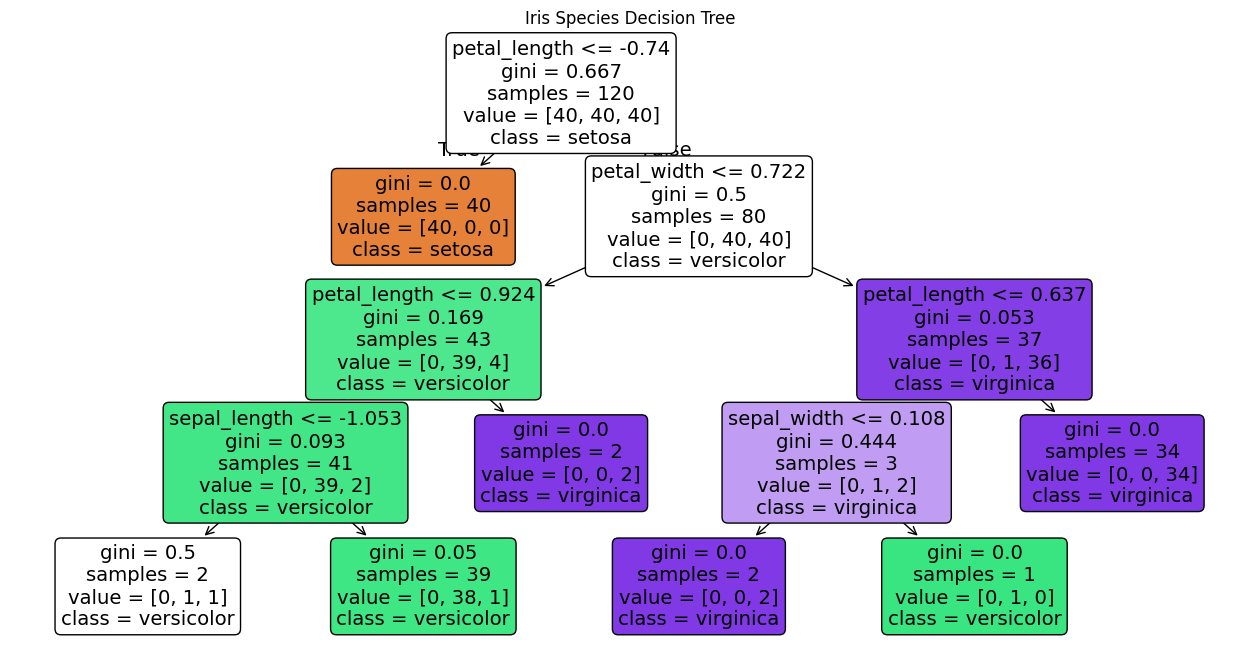

In [24]:
from sklearn.tree import plot_tree

tree_model = models["Decision Tree"].named_steps["model"]

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Iris Species Decision Tree")
plt.show()

In [25]:
best_model = results_df["F1-Score"].idxmax()

print("Best model based on macro F1-score:", best_model)
print(
    "Macro F1-score:",
    round(results_df.loc[best_model, "F1-Score"], 4)
)

Best model based on macro F1-score: Logistic Regression 
Macro F1-score: 0.9666


This project implemented a multi-class classification pipeline using the Iris dataset. Logistic Regression and Decision Tree models were trained using an 80:20 train-test split. The models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices. Exploratory data analysis and visualizations were used to understand the dataset and compare model performance. The model with the highest macro F1-score was identified as the best-performing model on the test set.